# Clasificación de noticias (AG News) — 4 modelos en PyTorch

**Proyecto final · Deep Learning**

Este notebook entrena **cuatro modelos** sobre AG News y guarda **checkpoints después de cada época**,
de modo que si Kaggle corta la sesión a mitad del entrenamiento, al volver a ejecutar se **reanuda
automáticamente** desde la última época completada.

Modelos:

1. **BiLSTM + atención entrenada desde cero** (red recurrente, sin pesos preentrenados) — *modelo base 1*.
2. **TF-IDF + Regresión Softmax** (regresión logística multinomial en PyTorch) — *modelo base 2, versión final*.
3. **DistilBERT ajustado (fine-tuning)** — *modelo estado del arte*.
4. **NewsHybridNet** — arquitectura propia de doble rama (semántica secuencial + léxica de subpalabras) con fusión por compuerta.

### Qué se guarda por modelo (requisito obligatorio)
Dentro de `OUTPUT_DIR/checkpoints/<modelo>/`:
- `last.pt` — se sobrescribe tras **cada época** (modelo, optimizador, scheduler, época, métricas, estados RNG).
- `best.pt` — mejor macro-F1 de validación visto hasta el momento.
- `history.json` — curvas de loss y métricas por época.
- Artefactos auxiliares (vocabulario, vectorizador TF-IDF, tokenizer, embeddings) para poder servir el modelo luego vía API.

La reanudación es automática: si existe `last.pt`, el entrenamiento continúa desde la época siguiente.


## 0. Instalación de dependencias

En Kaggle, `torch`, `scikit-learn`, `datasets` y `transformers` suelen venir preinstalados.
Esta celda solo asegura versiones compatibles; si ya están, no hace nada costoso.
Activa internet en el panel de Kaggle (**Settings → Internet: On**) para descargar el dataset y DistilBERT.

In [1]:
# Descomenta si hace falta instalar/actualizar en tu entorno de Kaggle.
# !pip install -q -U "transformers>=4.40" "datasets>=2.19" "scikit-learn>=1.3"

import importlib, sys
for pkg in ["torch", "sklearn", "datasets", "transformers"]:
    try:
        m = importlib.import_module(pkg)
        print(f"{pkg:14s} OK  ->", getattr(m, "__version__", "?"))
    except Exception as e:
        print(f"{pkg:14s} FALTA ->", e)


torch          OK  -> 2.11.0+cu130
sklearn        OK  -> 1.6.1
datasets       OK  -> 4.8.5
transformers   OK  -> 5.20.2


## 1. Configuración global, semillas y rutas de checkpoint

`OUTPUT_DIR` apunta a `/kaggle/working` cuando se ejecuta en Kaggle (ese directorio se conserva como
*output* del notebook). Si no existe, cae a una carpeta local `./outputs`, así el notebook también
corre fuera de Kaggle.

In [2]:
import os, json, time, random, math, re, zlib
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ---- Reproducibilidad ----
SEED = 30

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

os.environ["PYTHONHASHSEED"]="0"

# ---- Dispositivo ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ---- Rutas ----
if Path("/kaggle/working").exists():
    OUTPUT_DIR = Path("/kaggle/working")
else:
    OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CKPT_ROOT = OUTPUT_DIR / "checkpoints"
CKPT_ROOT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["World", "Sports", "Business", "Sci/Tech"]
NUM_CLASSES = len(CLASS_NAMES)

print("OUTPUT_DIR :", OUTPUT_DIR)
print("CKPT_ROOT  :", CKPT_ROOT)


Dispositivo: cuda
GPU: Tesla T4
OUTPUT_DIR : /kaggle/working
CKPT_ROOT  : /kaggle/working/checkpoints


## 2. Carga del dataset AG News y partición train/val/test

Se carga `fancyzhx/ag_news` desde Hugging Face `datasets`. Se separa un **10 % estratificado** del
entrenamiento como validación (semilla fija), dejando ~108.000 train / ~12.000 val, y se reserva el
test oficial (7.600) para el final, tal como describe el anteproyecto.

In [3]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split

raw = load_dataset("fancyzhx/ag_news")
print(raw)

train_text_all = [t for t in raw["train"]["text"]]
train_label_all = [int(y) for y in raw["train"]["label"]]
test_text = [t for t in raw["test"]["text"]]
test_label = [int(y) for y in raw["test"]["label"]]

train_text, val_text, train_label, val_label = train_test_split(
    train_text_all, train_label_all,
    test_size=0.10, random_state=SEED, stratify=train_label_all,
)

print(f"train: {len(train_text):>6}  val: {len(val_text):>6}  test: {len(test_text):>6}")
print("Ejemplo:", train_text[0][:120], "-> clase", CLASS_NAMES[train_label[0]])


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
train: 108000  val:  12000  test:   7600
Ejemplo: Jets Hardly Miss a Beat With the Line So in Tune IN football terms, it #39;s simply known as an offensive line, but Jets -> clase Sports


## 3. Utilidades de checkpoint y métricas (compartidas por los 4 modelos)

El corazón del requisito: `save_checkpoint` escribe de forma **atómica** (archivo temporal + `os.replace`)
para que un corte justo durante el guardado no deje un checkpoint corrupto. `load_checkpoint` restaura
modelo, optimizador, scheduler, época y estados de los generadores aleatorios.

In [4]:
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

def compute_metrics(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
    }

def rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }

def set_rng_state(state):
    try:
        random.setstate(state["python"])
        np.random.set_state(state["numpy"])
        torch.set_rng_state(state["torch"])
        if state.get("cuda") is not None and torch.cuda.is_available():
            torch.cuda.set_rng_state_all(state["cuda"])
    except Exception as e:
        print("Aviso: no se pudo restaurar RNG por completo:", e)

def atomic_save(obj, path: Path):
    """Guarda de forma atómica para no corromper el archivo si la sesión se corta."""
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)  # reemplazo atómico en el mismo sistema de archivos

def save_checkpoint(ckpt_dir: Path, model, optimizer, scheduler, epoch,
                    best_metric, history, extra=None, is_best=False):
    ckpt_dir = Path(ckpt_dir)
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    payload = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "scheduler_state": scheduler.state_dict() if scheduler is not None else None,
        "best_metric": best_metric,
        "rng_state": rng_state(),
        "extra": extra or {},
    }
    atomic_save(payload, ckpt_dir / "last.pt")
    with open(ckpt_dir / "history.json", "w") as f:
        json.dump(history, f, indent=2)
    if is_best:
        atomic_save(payload, ckpt_dir / "best.pt")
    print(f"  [checkpoint] epoca {epoch} guardada en {ckpt_dir}"
          + ("  (NUEVO MEJOR)" if is_best else ""))

def load_checkpoint(ckpt_dir: Path, model, optimizer=None, scheduler=None, map_location=None):
    """Devuelve (start_epoch, best_metric, history). Si no hay checkpoint, (0, -inf, [])."""
    ckpt_dir = Path(ckpt_dir)
    last = ckpt_dir / "last.pt"
    hist_path = ckpt_dir / "history.json"
    history = []
    if hist_path.exists():
        try:
            history = json.load(open(hist_path))
        except Exception:
            history = []
    if not last.exists():
        print(f"  [reanudar] no hay checkpoint en {ckpt_dir}; empezando desde cero.")
        return 0, float("-inf"), history
    ckpt = torch.load(last, map_location=map_location or DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state"):
        optimizer.load_state_dict(ckpt["optimizer_state"])
    if scheduler is not None and ckpt.get("scheduler_state"):
        scheduler.load_state_dict(ckpt["scheduler_state"])
    set_rng_state(ckpt["rng_state"])
    start_epoch = int(ckpt["epoch"])  # ya completada -> seguimos en la siguiente
    best_metric = ckpt.get("best_metric", float("-inf"))
    print(f"  [reanudar] checkpoint encontrado: epoca {start_epoch} completada, "
          f"best_macro_f1={best_metric:.4f}. Continuando desde la epoca {start_epoch+1}.")
    return start_epoch, best_metric, history


## 4. Modelo 1 — BiLSTM + atención (entrenado desde cero)

Red recurrente **sin ningún peso preentrenado**: la capa de embedding se inicializa al azar y se
aprende durante el entrenamiento. Arquitectura: `Embedding → BiLSTM → atención aditiva → MLP → softmax`.

### 4.1 Vocabulario y tokenización por palabras

In [5]:
from collections import Counter

PAD, UNK = "<pad>", "<unk>"
MAX_LEN = 80          # longitud de secuencia en palabras (como en el anteproyecto)
MIN_FREQ = 2
MAX_VOCAB = 40000

_token_re = re.compile(r"[a-z0-9]+|[^\sa-z0-9]")

def tokenize(text):
    return _token_re.findall(text.lower())

def build_vocab(texts, min_freq=MIN_FREQ, max_vocab=MAX_VOCAB):
    counter = Counter()
    for t in texts:
        counter.update(tokenize(t))
    itos = [PAD, UNK]
    for tok, c in counter.most_common():
        if c < min_freq or len(itos) >= max_vocab:
            break
        itos.append(tok)
    stoi = {tok: i for i, tok in enumerate(itos)}
    return stoi, itos

# El vocabulario se construye SOLO con el conjunto de entrenamiento.
stoi, itos = build_vocab(train_text)
PAD_IDX = stoi[PAD]
print("Tamano de vocabulario:", len(itos))

def encode(text, max_len=MAX_LEN):
    ids = [stoi.get(tok, stoi[UNK]) for tok in tokenize(text)][:max_len]
    length = len(ids)
    if length < max_len:
        ids = ids + [PAD_IDX] * (max_len - length)
    return ids, max(length, 1)

# Guardar el vocabulario para reconstruir el modelo al servir la API.
vocab_path = CKPT_ROOT / "rnn_scratch"
vocab_path.mkdir(parents=True, exist_ok=True)
with open(vocab_path / "vocab.json", "w") as f:
    json.dump({"itos": itos, "max_len": MAX_LEN, "pad_idx": PAD_IDX}, f)
print("Vocabulario guardado en", vocab_path / "vocab.json")


Tamano de vocabulario: 40000
Vocabulario guardado en /kaggle/working/checkpoints/rnn_scratch/vocab.json


### 4.2 Dataset y DataLoaders para la RNN

In [6]:
class AGNewsSeqDataset(Dataset):
    def __init__(self, texts, labels, max_len=MAX_LEN):
        self.texts = texts
        self.labels = labels
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        ids, length = encode(self.texts[i], self.max_len)
        return (torch.tensor(ids, dtype=torch.long),
                torch.tensor(length, dtype=torch.long),
                torch.tensor(self.labels[i], dtype=torch.long))

BATCH_SIZE_RNN = 128

train_ds = AGNewsSeqDataset(train_text, train_label)
val_ds   = AGNewsSeqDataset(val_text, val_label)
test_ds  = AGNewsSeqDataset(test_text, test_label)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE_RNN, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
print("Batches train:", len(train_loader))


Batches train: 844


### 4.3 Definición del modelo

In [7]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.proj = nn.Linear(hidden_dim, hidden_dim)
        self.context = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, h, mask):
        # h: (B, L, H)  mask: (B, L) con 1 en tokens reales
        scores = self.context(torch.tanh(self.proj(h))).squeeze(-1)  # (B, L)
        scores = scores.masked_fill(mask == 0, float("-inf"))
        weights = torch.softmax(scores, dim=1)                       # (B, L)
        pooled = torch.bmm(weights.unsqueeze(1), h).squeeze(1)       # (B, H)
        return pooled, weights

class BiLSTMAttentionClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=200, hidden_dim=256,
                 num_classes=NUM_CLASSES, pad_idx=PAD_IDX, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=1,
                            batch_first=True, bidirectional=True)
        self.attn = AdditiveAttention(hidden_dim * 2)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(128, num_classes),
        )
        self.pad_idx = pad_idx

    def forward(self, x, lengths):
        mask = (x != self.pad_idx).long()                  # (B, L)
        emb = self.embedding(x)                            # (B, L, E)
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        pooled, _ = self.attn(out, mask)
        return self.fc(self.dropout(pooled))

set_seed()
rnn_model = BiLSTMAttentionClassifier(len(itos)).to(DEVICE)
n_params = sum(p.numel() for p in rnn_model.parameters() if p.requires_grad)
print(rnn_model)
print(f"Parametros entrenables: {n_params:,}")


BiLSTMAttentionClassifier(
  (embedding): Embedding(40000, 200, padding_idx=0)
  (lstm): LSTM(200, 256, batch_first=True, bidirectional=True)
  (attn): AdditiveAttention(
    (proj): Linear(in_features=512, out_features=512, bias=True)
    (context): Linear(in_features=512, out_features=1, bias=False)
  )
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=4, bias=True)
  )
)
Parametros entrenables: 9,267,332


### 4.4 Bucle de entrenamiento con reanudación y checkpoint por época

In [8]:
@torch.no_grad()
def evaluate_rnn(model, loader):
    model.eval()
    ys, ps, total_loss, n = [], [], 0.0, 0
    crit = nn.CrossEntropyLoss()
    for x, lengths, y in loader:
        x, lengths, y = x.to(DEVICE), lengths.to(DEVICE), y.to(DEVICE)
        logits = model(x, lengths)
        total_loss += crit(logits, y).item() * y.size(0)
        n += y.size(0)
        ps.extend(logits.argmax(1).cpu().tolist())
        ys.extend(y.cpu().tolist())
    m = compute_metrics(ys, ps)
    m["loss"] = total_loss / n
    return m, ys, ps

def train_rnn(model, epochs=12, lr=1e-3, patience=3):
    ckpt_dir = CKPT_ROOT / "rnn_scratch"
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    start_epoch, best_f1, history = load_checkpoint(ckpt_dir, model, optimizer, scheduler)
    bad = 0

    for epoch in range(start_epoch + 1, epochs + 1):
        model.train()
        t0 = time.time()
        running = 0.0
        for x, lengths, y in train_loader:
            x, lengths, y = x.to(DEVICE), lengths.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(x, lengths), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running += loss.item() * y.size(0)
        scheduler.step()
        train_loss = running / len(train_ds)
        val_m, _, _ = evaluate_rnn(model, val_loader)
        dt = time.time() - t0
        print(f"Epoca {epoch:02d}/{epochs} | train_loss {train_loss:.4f} | "
              f"val_loss {val_m['loss']:.4f} | val_acc {val_m['accuracy']:.4f} | "
              f"val_macroF1 {val_m['macro_f1']:.4f} | {dt:.1f}s")

        history.append({"epoch": epoch, "train_loss": train_loss, "epoch_seconds": dt, **val_m})
        is_best = val_m["macro_f1"] > best_f1
        if is_best:
            best_f1 = val_m["macro_f1"]; bad = 0
        else:
            bad += 1
        # >>> checkpoint DESPUES de cada epoca <<<
        save_checkpoint(ckpt_dir, model, optimizer, scheduler, epoch,
                        best_f1, history, is_best=is_best)
        if bad >= patience:
            print(f"Early stopping en epoca {epoch} (sin mejora {patience} epocas).")
            break
    return history

rnn_history = train_rnn(rnn_model, epochs=12)


  [reanudar] no hay checkpoint en /kaggle/working/checkpoints/rnn_scratch; empezando desde cero.
Epoca 01/12 | train_loss 0.6645 | val_loss 0.3347 | val_acc 0.8971 | val_macroF1 0.8967 | 42.1s
  [checkpoint] epoca 1 guardada en /kaggle/working/checkpoints/rnn_scratch  (NUEVO MEJOR)
Epoca 02/12 | train_loss 0.5171 | val_loss 0.2882 | val_acc 0.9167 | val_macroF1 0.9168 | 39.5s
  [checkpoint] epoca 2 guardada en /kaggle/working/checkpoints/rnn_scratch  (NUEVO MEJOR)
Epoca 03/12 | train_loss 0.4736 | val_loss 0.2781 | val_acc 0.9173 | val_macroF1 0.9173 | 39.8s
  [checkpoint] epoca 3 guardada en /kaggle/working/checkpoints/rnn_scratch  (NUEVO MEJOR)
Epoca 04/12 | train_loss 0.4421 | val_loss 0.2767 | val_acc 0.9178 | val_macroF1 0.9176 | 39.5s
  [checkpoint] epoca 4 guardada en /kaggle/working/checkpoints/rnn_scratch  (NUEVO MEJOR)
Epoca 05/12 | train_loss 0.4165 | val_loss 0.2869 | val_acc 0.9191 | val_macroF1 0.9192 | 39.7s
  [checkpoint] epoca 5 guardada en /kaggle/working/checkpoints/

### 4.5 Evaluación en test (carga del mejor checkpoint)

In [9]:
def eval_best_rnn():
    ckpt_dir = CKPT_ROOT / "rnn_scratch"
    best = torch.load(ckpt_dir / "best.pt", map_location=DEVICE, weights_only=False)
    rnn_model.load_state_dict(best["model_state"])
    m, ys, ps = evaluate_rnn(rnn_model, test_loader)
    print("== RNN desde cero · TEST ==")
    print(f"accuracy={m['accuracy']:.4f}  macro_f1={m['macro_f1']:.4f}")
    print(classification_report(ys, ps, target_names=CLASS_NAMES, digits=4))
    return m

rnn_test = eval_best_rnn()


== RNN desde cero · TEST ==
accuracy=0.9239  macro_f1=0.9241
              precision    recall  f1-score   support

       World     0.9400    0.9242    0.9321      1900
      Sports     0.9694    0.9679    0.9687      1900
    Business     0.8804    0.9068    0.8934      1900
    Sci/Tech     0.9073    0.8968    0.9021      1900

    accuracy                         0.9239      7600
   macro avg     0.9243    0.9239    0.9241      7600
weighted avg     0.9243    0.9239    0.9241      7600



## 5. Modelo 2 — TF-IDF + Regresión Softmax

Línea base clásica en su **versión final**: se vectoriza el texto con TF-IDF (unigramas + bigramas) y
se entrena una **regresión logística multinomial** implementada como una capa lineal + softmax en
PyTorch, optimizada con AdamW. También aquí se **guarda un checkpoint por época** y se reanuda solo.

### 5.1 Vectorización TF-IDF

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import csr_matrix
import joblib

tfidf = TfidfVectorizer(
    lowercase=True, ngram_range=(1, 2),
    min_df=5, max_features=50000, sublinear_tf=True,
)
X_train = tfidf.fit_transform(train_text)
X_val   = tfidf.transform(val_text)
X_test  = tfidf.transform(test_text)
print("TF-IDF train shape:", X_train.shape)

tfidf_dir = CKPT_ROOT / "tfidf_softmax"
tfidf_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(tfidf, tfidf_dir / "tfidf_vectorizer.joblib")
print("Vectorizador TF-IDF guardado en", tfidf_dir / "tfidf_vectorizer.joblib")


TF-IDF train shape: (108000, 50000)
Vectorizador TF-IDF guardado en /kaggle/working/checkpoints/tfidf_softmax/tfidf_vectorizer.joblib


### 5.2 Dataset disperso y modelo softmax lineal

In [11]:
class SparseDataset(Dataset):
    def __init__(self, X_csr: csr_matrix, y):
        self.X = X_csr.tocsr()
        self.y = np.asarray(y, dtype=np.int64)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, i):
        row = self.X[i]
        dense = torch.from_numpy(row.toarray().ravel().astype(np.float32))
        return dense, torch.tensor(self.y[i], dtype=torch.long)

BATCH_SIZE_TFIDF = 256
INPUT_DIM = X_train.shape[1]

tfidf_train_loader = DataLoader(SparseDataset(X_train, train_label),
                                batch_size=BATCH_SIZE_TFIDF, shuffle=True, num_workers=2)
tfidf_val_loader   = DataLoader(SparseDataset(X_val, val_label),
                                batch_size=512, shuffle=False, num_workers=2)
tfidf_test_loader  = DataLoader(SparseDataset(X_test, test_label),
                                batch_size=512, shuffle=False, num_workers=2)

class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes=NUM_CLASSES):
        super().__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)

set_seed()
tfidf_model = SoftmaxRegression(INPUT_DIM).to(DEVICE)
print(f"Dimension de entrada TF-IDF: {INPUT_DIM:,}")


Dimension de entrada TF-IDF: 50,000


### 5.3 Entrenamiento con checkpoint por época y reanudación

In [12]:
@torch.no_grad()
def evaluate_tfidf(model, loader):
    model.eval()
    ys, ps, total_loss, n = [], [], 0.0, 0
    crit = nn.CrossEntropyLoss()
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += crit(logits, y).item() * y.size(0)
        n += y.size(0)
        ps.extend(logits.argmax(1).cpu().tolist())
        ys.extend(y.cpu().tolist())
    m = compute_metrics(ys, ps)
    m["loss"] = total_loss / n
    return m, ys, ps

def train_tfidf(model, epochs=15, lr=1e-2, weight_decay=1e-4, patience=3):
    ckpt_dir = CKPT_ROOT / "tfidf_softmax"
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss()

    start_epoch, best_f1, history = load_checkpoint(ckpt_dir, model, optimizer, scheduler)
    bad = 0

    for epoch in range(start_epoch + 1, epochs + 1):
        model.train()
        t0 = time.time(); running = 0.0
        for x, y in tfidf_train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item() * y.size(0)
        scheduler.step()
        train_loss = running / len(train_text)
        val_m, _, _ = evaluate_tfidf(model, tfidf_val_loader)
        dt = time.time() - t0
        print(f"Epoca {epoch:02d}/{epochs} | train_loss {train_loss:.4f} | "
              f"val_loss {val_m['loss']:.4f} | val_acc {val_m['accuracy']:.4f} | "
              f"val_macroF1 {val_m['macro_f1']:.4f} | {dt:.1f}s")

        history.append({"epoch": epoch, "train_loss": train_loss, "epoch_seconds": dt, **val_m})
        is_best = val_m["macro_f1"] > best_f1
        if is_best:
            best_f1 = val_m["macro_f1"]; bad = 0
        else:
            bad += 1
        save_checkpoint(ckpt_dir, model, optimizer, scheduler, epoch,
                        best_f1, history, is_best=is_best)
        if bad >= patience:
            print(f"Early stopping en epoca {epoch}.")
            break
    return history

tfidf_history = train_tfidf(tfidf_model, epochs=15)


  [reanudar] no hay checkpoint en /kaggle/working/checkpoints/tfidf_softmax; empezando desde cero.
Epoca 01/15 | train_loss 0.4861 | val_loss 0.3010 | val_acc 0.9127 | val_macroF1 0.9125 | 24.6s
  [checkpoint] epoca 1 guardada en /kaggle/working/checkpoints/tfidf_softmax  (NUEVO MEJOR)
Epoca 02/15 | train_loss 0.2291 | val_loss 0.2578 | val_acc 0.9187 | val_macroF1 0.9185 | 25.0s
  [checkpoint] epoca 2 guardada en /kaggle/working/checkpoints/tfidf_softmax  (NUEVO MEJOR)
Epoca 03/15 | train_loss 0.1723 | val_loss 0.2447 | val_acc 0.9193 | val_macroF1 0.9192 | 24.5s
  [checkpoint] epoca 3 guardada en /kaggle/working/checkpoints/tfidf_softmax  (NUEVO MEJOR)
Epoca 04/15 | train_loss 0.1388 | val_loss 0.2400 | val_acc 0.9179 | val_macroF1 0.9178 | 24.8s
  [checkpoint] epoca 4 guardada en /kaggle/working/checkpoints/tfidf_softmax
Epoca 05/15 | train_loss 0.1157 | val_loss 0.2392 | val_acc 0.9173 | val_macroF1 0.9171 | 24.8s
  [checkpoint] epoca 5 guardada en /kaggle/working/checkpoints/tfidf

### 5.4 Evaluación en test

In [13]:
def eval_best_tfidf():
    ckpt_dir = CKPT_ROOT / "tfidf_softmax"
    best = torch.load(ckpt_dir / "best.pt", map_location=DEVICE, weights_only=False)
    tfidf_model.load_state_dict(best["model_state"])
    m, ys, ps = evaluate_tfidf(tfidf_model, tfidf_test_loader)
    print("== TF-IDF + Softmax · TEST ==")
    print(f"accuracy={m['accuracy']:.4f}  macro_f1={m['macro_f1']:.4f}")
    print(classification_report(ys, ps, target_names=CLASS_NAMES, digits=4))
    return m

tfidf_test = eval_best_tfidf()


== TF-IDF + Softmax · TEST ==
accuracy=0.9197  macro_f1=0.9196
              precision    recall  f1-score   support

       World     0.9371    0.9021    0.9193      1900
      Sports     0.9584    0.9821    0.9701      1900
    Business     0.8842    0.8921    0.8881      1900
    Sci/Tech     0.8993    0.9026    0.9010      1900

    accuracy                         0.9197      7600
   macro avg     0.9198    0.9197    0.9196      7600
weighted avg     0.9198    0.9197    0.9196      7600



## 6. Modelo 3 — DistilBERT ajustado (fine-tuning)

Se parte de `distilbert-base-uncased`, se añade una cabeza de clasificación de 4 clases y se ajusta
toda la red. El entrenamiento usa **precisión mixta (AMP)** en GPU y, como los demás, guarda un
**checkpoint por época** con reanudación automática. Se guarda también el *tokenizer* para servir la API.

### 6.1 Tokenización y DataLoaders

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

MODEL_NAME = "distilbert-base-uncased"
MAX_TOKENS = 128
BATCH_SIZE_BERT = 32

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class AGNewsBertDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_TOKENS):
        self.texts = texts; self.labels = labels
        self.tok = tokenizer; self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        enc = self.tok(self.texts[i], truncation=True, max_length=self.max_len,
                       padding="max_length", return_tensors="pt")
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[i], dtype=torch.long),
        }

bert_train_loader = DataLoader(AGNewsBertDataset(train_text, train_label, bert_tokenizer),
                               batch_size=BATCH_SIZE_BERT, shuffle=True, num_workers=2, pin_memory=True)
bert_val_loader   = DataLoader(AGNewsBertDataset(val_text, val_label, bert_tokenizer),
                               batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
bert_test_loader  = DataLoader(AGNewsBertDataset(test_text, test_label, bert_tokenizer),
                               batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

bert_dir = CKPT_ROOT / "distilbert"
bert_dir.mkdir(parents=True, exist_ok=True)
bert_tokenizer.save_pretrained(bert_dir / "tokenizer")
print("Tokenizer guardado en", bert_dir / "tokenizer")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer guardado en /kaggle/working/checkpoints/distilbert/tokenizer


### 6.2 Modelo y entrenamiento con AMP, checkpoint por época y reanudación

In [15]:
set_seed()
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES,
    id2label={i: c for i, c in enumerate(CLASS_NAMES)},
    label2id={c: i for i, c in enumerate(CLASS_NAMES)},
).to(DEVICE)

@torch.no_grad()
def evaluate_bert(model, loader):
    model.eval()
    ys, ps, total_loss, n = [], [], 0.0, 0
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attn = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)
        out = model(input_ids=input_ids, attention_mask=attn, labels=labels)
        total_loss += out.loss.item() * labels.size(0); n += labels.size(0)
        ps.extend(out.logits.argmax(1).cpu().tolist())
        ys.extend(labels.cpu().tolist())
    m = compute_metrics(ys, ps); m["loss"] = total_loss / n
    return m, ys, ps

def train_bert(model, epochs=3, lr=2e-5, warmup_ratio=0.1, patience=2):
    ckpt_dir = CKPT_ROOT / "distilbert"
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    total_steps = len(bert_train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(total_steps * warmup_ratio), total_steps)
    use_amp = torch.cuda.is_available()
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    start_epoch, best_f1, history = load_checkpoint(ckpt_dir, model, optimizer, scheduler)
    bad = 0

    for epoch in range(start_epoch + 1, epochs + 1):
        model.train(); t0 = time.time(); running = 0.0; seen = 0
        for batch in bert_train_loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attn = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=use_amp):
                out = model(input_ids=input_ids, attention_mask=attn, labels=labels)
                loss = out.loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running += loss.item() * labels.size(0); seen += labels.size(0)
        train_loss = running / seen
        val_m, _, _ = evaluate_bert(model, bert_val_loader)
        dt = time.time() - t0
        print(f"Epoca {epoch:02d}/{epochs} | train_loss {train_loss:.4f} | "
              f"val_loss {val_m['loss']:.4f} | val_acc {val_m['accuracy']:.4f} | "
              f"val_macroF1 {val_m['macro_f1']:.4f} | {dt:.1f}s")

        history.append({"epoch": epoch, "train_loss": train_loss, "epoch_seconds": dt, **val_m})
        is_best = val_m["macro_f1"] > best_f1
        if is_best:
            best_f1 = val_m["macro_f1"]; bad = 0
        else:
            bad += 1
        save_checkpoint(ckpt_dir, model, optimizer, scheduler, epoch,
                        best_f1, history, is_best=is_best)
        # Guardar tambien en formato HuggingFace para servir facil la API.
        if is_best:
            model.save_pretrained(ckpt_dir / "hf_best")
        if bad >= patience:
            print(f"Early stopping en epoca {epoch}.")
            break
    return history

bert_history = train_bert(bert_model, epochs=3)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [reanudar] no hay checkpoint en /kaggle/working/checkpoints/distilbert; empezando desde cero.


/tmp/ipykernel_23/3912674168.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_23/3912674168.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_23/3912674168.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Epoca 03/3 | train_loss 0.0991 | val_loss 0.1813 | val_acc 0.9483 | val_macroF1 0.9482 | 408.7s
  [checkpoint] epoca 3 guardada en /kaggle/working/checkpoints/distilbert  (NUEVO MEJOR)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

### 6.3 Evaluación en test

In [16]:
def eval_best_bert():
    ckpt_dir = CKPT_ROOT / "distilbert"
    best = torch.load(ckpt_dir / "best.pt", map_location=DEVICE, weights_only=False)
    bert_model.load_state_dict(best["model_state"])
    m, ys, ps = evaluate_bert(bert_model, bert_test_loader)
    print("== DistilBERT ajustado · TEST ==")
    print(f"accuracy={m['accuracy']:.4f}  macro_f1={m['macro_f1']:.4f}")
    print(classification_report(ys, ps, target_names=CLASS_NAMES, digits=4))
    return m

bert_test = eval_best_bert()


== DistilBERT ajustado · TEST ==
accuracy=0.9455  macro_f1=0.9456
              precision    recall  f1-score   support

       World     0.9622    0.9521    0.9571      1900
      Sports     0.9884    0.9895    0.9890      1900
    Business     0.9232    0.9116    0.9174      1900
    Sci/Tech     0.9089    0.9289    0.9188      1900

    accuracy                         0.9455      7600
   macro avg     0.9457    0.9455    0.9456      7600
weighted avg     0.9457    0.9455    0.9456      7600



## 7. Modelo 4 — NewsHybridNet (arquitectura propuesta)

Implementación fiel a la sección 5.3 del anteproyecto. Red de **doble rama** con fusión por compuerta:

- **Rama A — semántica secuencial:** embeddings fastText de 300d **congelados** (OOV compuesto por
  subpalabras) → adaptador `Linear 300→256 + LayerNorm + GELU + SpatialDropout(0.2)` → tres `Conv1D`
  paralelas (kernels 2, 3, 5; 128 filtros; padding "same") → concatenación + `LayerNorm + ReLU` (384) →
  `BiGRU` 128+128 (256) → **atención aditiva enmascarada ‖ max-pooling temporal** → `h_A` (512).
- **Rama B — léxica de subpalabras:** n-gramas de caracteres n = 3..5 con *hashing* a 2¹⁷ = 131.072
  cubetas → `EmbeddingBag` (131072×64, agregación por media) → `h_B` (64).
- **Fusión con compuerta:** proyecciones `h_A→256` y `h_B→256`; `g = σ(W·[h_A,h_B]+b)`;
  `h = g ⊙ h_A' + (1 − g) ⊙ h_B'`.
- **Cabeza:** `Dropout(0.3) + Dense 256→128 + GELU → Dense 128→4 → Softmax`.

Entrenamiento (sección 5.8): CE con *label smoothing* 0.1, AdamW `lr=1e-3`, `weight_decay=1e-2`
(sin decay en LayerNorm y sesgos), scheduler coseno con *warmup*, lote 128, 10–15 épocas con early
stopping (paciencia 3) y recorte de gradiente a 1.0. Igual que los otros modelos, **guarda checkpoint
por época y se reanuda automáticamente**.


### 7.1 Embeddings fastText congelados (con composición de subpalabras para OOV)

El anteproyecto exige embeddings fastText **congelados** y que las palabras fuera de vocabulario reciban
el vector que fastText compone a partir de sus subpalabras. Eso solo es posible con el modelo `.bin`
(formato Facebook), no con el `.vec`. La celda intenta, en este orden:

1. un `.bin` de fastText ya presente en Kaggle (añade el dataset *fasttext-english* a tu notebook), o
2. descargarlo con la librería `gensim` / `fasttext` si hay internet.

Si no se encuentra ninguno, se construye una matriz **aleatoria congelada** como respaldo para que el
notebook no se rompa, dejando un aviso explícito: en ese caso la rama A no usa conocimiento preentrenado
y el resultado no corresponde a la configuración propuesta. Define `FASTTEXT_BIN_PATH` si tu `.bin`
está en otra ruta.

In [17]:
# Reutiliza el vocabulario por palabras (itos/stoi/MAX_LEN) construido para el modelo 1.
EMB_DIM = 300
FASTTEXT_BIN_PATH = None  # p.ej. "/kaggle/input/fasttext-english/wiki-news-300d-1M-subword.bin"

_CANDIDATE_BINS = [
    FASTTEXT_BIN_PATH,
    "/kaggle/input/datasets/sanyatargrenkin/cc-en-300-bin/cc.en.300.bin",
    "/kaggle/input/fasttext-english/wiki-news-300d-1M-subword.bin",
    "/kaggle/input/fasttext-wikinews/wiki-news-300d-1M-subword.bin",
    "/kaggle/input/fasttext/cc.en.300.bin",
    "/kaggle/input/fasttextenglish/crawl-300d-2M-subword.bin",
]

def _load_fasttext_model():
    """Devuelve un objeto con metodo get_vector(word)->np.ndarray(300,) o None."""
    import numpy as np
    # 1) .bin local via libreria oficial fasttext (mejor manejo de subwords/OOV)
    for path in _CANDIDATE_BINS:
        if path and os.path.exists(path):
            try:
                import fasttext
                ft = fasttext.load_model(path)
                print("fastText (.bin) cargado con libreria 'fasttext':", path)
                class _W:
                    def get_vector(self, w): return ft.get_word_vector(w)
                return _W()
            except Exception as e:
                print("No se pudo cargar con 'fasttext' (", e, "); intento gensim...")
                try:
                    from gensim.models.fasttext import load_facebook_vectors
                    kv = load_facebook_vectors(path)
                    print("fastText (.bin) cargado con gensim:", path)
                    class _W:
                        def get_vector(self, w):
                            try: return kv.get_vector(w)
                            except Exception: return np.zeros(EMB_DIM, dtype=np.float32)
                    return _W()
                except Exception as e2:
                    print("gensim tambien fallo:", e2)
    # 2) Descargar con gensim.downloader (requiere internet). Nota: la version .vec de
    #    gensim-data NO compone OOV, pero sirve como aproximacion si no hay .bin.
    try:
        import gensim.downloader as api
        print("Descargando 'fasttext-wiki-news-subwords-300' via gensim.downloader (puede tardar)...")
        kv = api.load("fasttext-wiki-news-subwords-300")
        class _W:
            def get_vector(self, w):
                try: return kv.get_vector(w)
                except Exception: return np.zeros(EMB_DIM, dtype=np.float32)
        return _W()
    except Exception as e:
        print("No se pudo descargar via gensim.downloader:", e)
    return None

def build_embedding_matrix(itos, dim=EMB_DIM):
    import numpy as np
    ft = _load_fasttext_model()
    matrix = np.random.normal(0.0, 0.1, size=(len(itos), dim)).astype(np.float32)
    matrix[PAD_IDX] = 0.0
    if ft is None:
        print("\n*** AVISO: no se encontro fastText. Se usa matriz ALEATORIA congelada. ***")
        print("*** Esto NO corresponde a la configuracion propuesta (rama A sin preentrenamiento). ***")
        return matrix, False
    hits = 0
    for i, tok in enumerate(itos):
        if tok in ("<pad>", "<unk>"):
            continue
        try:
            vec = ft.get_vector(tok)  # fastText compone OOV por subpalabras
            if vec is not None and np.linalg.norm(vec) > 0:
                matrix[i] = vec[:dim]; hits += 1
        except Exception:
            pass
    print(f"Vectores fastText asignados: {hits}/{len(itos)} ({100*hits/len(itos):.1f}%)")
    return matrix, True

emb_matrix, USED_FASTTEXT = build_embedding_matrix(itos)
emb_tensor = torch.tensor(emb_matrix)
print("Matriz de embeddings:", tuple(emb_tensor.shape), "| fastText:", USED_FASTTEXT)


fastText (.bin) cargado con libreria 'fasttext': /kaggle/input/datasets/sanyatargrenkin/cc-en-300-bin/cc.en.300.bin
Vectores fastText asignados: 39997/40000 (100.0%)
Matriz de embeddings: (40000, 300) | fastText: True


### 7.2 Preprocesamiento de la rama B — n-gramas de caracteres con *hashing*

Para cada texto se extraen n-gramas de caracteres (n = 3, 4, 5) sobre el texto normalizado y se mapean
a cubetas mediante *hashing* a 2¹⁷ = 131.072, tal como indica el anteproyecto. El `Dataset` produce,
por ejemplo, la secuencia de palabras (para la rama A) y la bolsa de índices de n-gramas (para la rama B).

In [18]:
NGRAM_BUCKETS = 2 ** 17          # 131072 cubetas de hashing
CHAR_NGRAMS = (3, 4, 5)

_norm_re = re.compile(r"\s+")

def _normalize_for_ngrams(text):
    return _norm_re.sub(" ", text.lower()).strip()

def char_ngram_hashes(text, buckets=NGRAM_BUCKETS, ns=CHAR_NGRAMS):
    s = "<" + _normalize_for_ngrams(text) + ">"
    idxs = []
    for n in ns:
        if len(s) < n:
            continue
        for i in range(len(s) - n + 1):
            gram = s[i:i + n]
            idxs.append(zlib.crc32(gram.encode("utf-8")) % buckets)
    if not idxs:
        idxs = [0]
    return idxs

class AGNewsHybridDataset(Dataset):
    def __init__(self, texts, labels, max_len=MAX_LEN):
        self.texts = texts; self.labels = labels; self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        ids, length = encode(self.texts[i], self.max_len)      # rama A (palabras)
        ngrams = char_ngram_hashes(self.texts[i])              # rama B (n-gramas char)
        return (torch.tensor(ids, dtype=torch.long),
                torch.tensor(length, dtype=torch.long),
                torch.tensor(ngrams, dtype=torch.long),
                torch.tensor(self.labels[i], dtype=torch.long))

def hybrid_collate(batch):
    """Empaqueta la bolsa de n-gramas en el formato de EmbeddingBag (valores + offsets)."""
    ids = torch.stack([b[0] for b in batch])
    lengths = torch.stack([b[1] for b in batch])
    labels = torch.stack([b[3] for b in batch])
    ngram_lists = [b[2] for b in batch]
    offsets = torch.zeros(len(ngram_lists), dtype=torch.long)
    acc = 0
    for j, g in enumerate(ngram_lists):
        offsets[j] = acc; acc += g.numel()
    values = torch.cat(ngram_lists) if ngram_lists else torch.zeros(1, dtype=torch.long)
    return ids, lengths, values, offsets, labels

BATCH_SIZE_HYBRID = 128
hyb_train_loader = DataLoader(AGNewsHybridDataset(train_text, train_label),
                              batch_size=BATCH_SIZE_HYBRID, shuffle=True,
                              num_workers=2, pin_memory=True, collate_fn=hybrid_collate)
hyb_val_loader   = DataLoader(AGNewsHybridDataset(val_text, val_label),
                              batch_size=256, shuffle=False,
                              num_workers=2, pin_memory=True, collate_fn=hybrid_collate)
hyb_test_loader  = DataLoader(AGNewsHybridDataset(test_text, test_label),
                              batch_size=256, shuffle=False,
                              num_workers=2, pin_memory=True, collate_fn=hybrid_collate)
print("Batches train (hybrid):", len(hyb_train_loader))


Batches train (hybrid): 844


### 7.3 Definición de NewsHybridNet (capa por capa, según la tabla 5.3.2)

In [19]:
class SpatialDropout1d(nn.Module):
    """Dropout que elimina canales completos a lo largo del tiempo (B, L, C)."""
    def __init__(self, p):
        super().__init__(); self.drop = nn.Dropout2d(p)

    def forward(self, x):                 # x: (B, L, C)
        x = x.permute(0, 2, 1).unsqueeze(-1)   # (B, C, L, 1)
        x = self.drop(x)
        return x.squeeze(-1).permute(0, 2, 1)  # (B, L, C)

class MaskedAdditiveAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)
        self.context = nn.Linear(dim, 1, bias=False)

    def forward(self, h, mask):           # h: (B, L, D)  mask: (B, L)
        scores = self.context(torch.tanh(self.proj(h))).squeeze(-1)
        scores = scores.masked_fill(mask == 0, float("-inf"))
        w = torch.softmax(scores, dim=1)
        pooled = torch.bmm(w.unsqueeze(1), h).squeeze(1)
        return pooled, w

class NewsHybridNet(nn.Module):
    def __init__(self, emb_matrix, num_classes=NUM_CLASSES, pad_idx=PAD_IDX,
                 ngram_buckets=NGRAM_BUCKETS):
        super().__init__()
        vocab_size, emb_dim = emb_matrix.shape
        self.pad_idx = pad_idx

        # --- Rama A: semantica secuencial ---
        # A1: embeddings fastText CONGELADOS
        self.embedding = nn.Embedding.from_pretrained(
            emb_matrix, freeze=True, padding_idx=pad_idx)
        # A2: adaptador 300 -> 256 + LayerNorm + GELU + spatial dropout 0.2
        self.adapter = nn.Linear(emb_dim, 256)
        self.adapter_ln = nn.LayerNorm(256)
        self.spatial_drop = SpatialDropout1d(0.2)
        # A3: tres Conv1D paralelas (k=2,3,5; 128 filtros; padding "same")
        self.conv2 = nn.Conv1d(256, 128, kernel_size=2, padding="same")
        self.conv3 = nn.Conv1d(256, 128, kernel_size=3, padding="same")
        self.conv5 = nn.Conv1d(256, 128, kernel_size=5, padding="same")
        # A4: concat (384) + LayerNorm + ReLU
        self.cat_ln = nn.LayerNorm(384)
        # A5: BiGRU 128+128 -> 256
        self.bigru = nn.GRU(384, 128, num_layers=1, batch_first=True, bidirectional=True)
        # A6: atencion aditiva enmascarada || max-pooling temporal -> 512
        self.attn = MaskedAdditiveAttention(256)

        # --- Rama B: lexica de subpalabras ---
        self.embbag = nn.EmbeddingBag(ngram_buckets, 64, mode="mean")

        # --- Fusion con compuerta ---
        self.proj_a = nn.Linear(512, 256)   # h_A -> 256
        self.proj_b = nn.Linear(64, 256)    # h_B -> 256
        self.gate = nn.Linear(512, 256)     # g = sigma(W[h_A',h_B'] + b)

        # --- Cabeza ---
        self.head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(256, 128), nn.GELU(), nn.Linear(128, num_classes),
        )

    def forward(self, x, lengths, ngram_values, ngram_offsets, return_gate=False):
        mask = (x != self.pad_idx).long()                 # (B, L)
        # Rama A
        emb = self.embedding(x)                           # (B, L, 300)
        a = F.gelu(self.adapter_ln(self.adapter(emb)))    # (B, L, 256)
        a = self.spatial_drop(a)
        a_t = a.transpose(1, 2)                           # (B, 256, L)
        c = torch.cat([self.conv2(a_t), self.conv3(a_t), self.conv5(a_t)], dim=1)  # (B,384,L)
        c = c.transpose(1, 2)                             # (B, L, 384)
        c = F.relu(self.cat_ln(c))
        packed = nn.utils.rnn.pack_padded_sequence(
            c, lengths.cpu(), batch_first=True, enforce_sorted=False)
        g_out, _ = self.bigru(packed)
        g_out, _ = nn.utils.rnn.pad_packed_sequence(
            g_out, batch_first=True, total_length=x.size(1))   # (B, L, 256)
        att, _ = self.attn(g_out, mask)                   # (B, 256)
        masked = g_out.masked_fill((mask == 0).unsqueeze(-1), float("-inf"))
        maxp, _ = masked.max(dim=1)                       # (B, 256)
        maxp = torch.nan_to_num(maxp, neginf=0.0)
        h_a = torch.cat([att, maxp], dim=1)               # (B, 512)

        # Rama B
        h_b = self.embbag(ngram_values, ngram_offsets)    # (B, 64)

        # Fusion con compuerta
        ha_p = self.proj_a(h_a)                           # (B, 256)
        hb_p = self.proj_b(h_b)                           # (B, 256)
        g = torch.sigmoid(self.gate(torch.cat([ha_p, hb_p], dim=1)))  # (B, 256)
        fused = g * ha_p + (1 - g) * hb_p                 # (B, 256)

        logits = self.head(fused)
        if return_gate:
            return logits, g
        return logits

set_seed()
hybrid_model = NewsHybridNet(emb_tensor).to(DEVICE)
total_p = sum(p.numel() for p in hybrid_model.parameters())
train_p = sum(p.numel() for p in hybrid_model.parameters() if p.requires_grad)
print(hybrid_model)
print(f"Parametros totales: {total_p:,} | entrenables: {train_p:,} | congelados: {total_p-train_p:,}")


NewsHybridNet(
  (embedding): Embedding(40000, 300, padding_idx=0)
  (adapter): Linear(in_features=300, out_features=256, bias=True)
  (adapter_ln): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (spatial_drop): SpatialDropout1d(
    (drop): Dropout2d(p=0.2, inplace=False)
  )
  (conv2): Conv1d(256, 128, kernel_size=(2,), stride=(1,), padding=same)
  (conv3): Conv1d(256, 128, kernel_size=(3,), stride=(1,), padding=same)
  (conv5): Conv1d(256, 128, kernel_size=(5,), stride=(1,), padding=same)
  (cat_ln): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
  (bigru): GRU(384, 128, batch_first=True, bidirectional=True)
  (attn): MaskedAdditiveAttention(
    (proj): Linear(in_features=256, out_features=256, bias=True)
    (context): Linear(in_features=256, out_features=1, bias=False)
  )
  (embbag): EmbeddingBag(131072, 64, mode='mean')
  (proj_a): Linear(in_features=512, out_features=256, bias=True)
  (proj_b): Linear(in_features=64, out_features=256, bias=True)
  (gate): Linea

### 7.4 Entrenamiento con checkpoint por época y reanudación

Se excluyen `LayerNorm` y sesgos del *weight decay* (como pide la sección 5.8) y se guardan, además del
checkpoint, los artefactos para servir la API: vocabulario, matriz de embeddings y la config de n-gramas.

In [20]:
def build_param_groups(model, weight_decay=1e-2):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim == 1 or name.endswith(".bias") or "ln" in name.lower() or "norm" in name.lower():
            no_decay.append(p)
        else:
            decay.append(p)
    return [{"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0}]

@torch.no_grad()
def evaluate_hybrid(model, loader):
    model.eval()
    ys, ps, total_loss, n = [], [], 0.0, 0
    crit = nn.CrossEntropyLoss()
    for ids, lengths, vals, offs, y in loader:
        ids, lengths = ids.to(DEVICE), lengths.to(DEVICE)
        vals, offs, y = vals.to(DEVICE), offs.to(DEVICE), y.to(DEVICE)
        logits = model(ids, lengths, vals, offs)
        total_loss += crit(logits, y).item() * y.size(0); n += y.size(0)
        ps.extend(logits.argmax(1).cpu().tolist()); ys.extend(y.cpu().tolist())
    m = compute_metrics(ys, ps); m["loss"] = total_loss / n
    return m, ys, ps

def save_hybrid_artifacts(ckpt_dir):
    import numpy as np
    np.save(ckpt_dir / "embeddings.npy", emb_matrix)
    with open(ckpt_dir / "vocab.json", "w") as f:
        json.dump({"itos": itos, "max_len": MAX_LEN, "pad_idx": PAD_IDX}, f)
    with open(ckpt_dir / "ngram_config.json", "w") as f:
        json.dump({"buckets": NGRAM_BUCKETS, "ns": list(CHAR_NGRAMS)}, f)

def train_hybrid(model, epochs=12, lr=1e-3, patience=3):
    ckpt_dir = CKPT_ROOT / "newshybridnet"
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    save_hybrid_artifacts(ckpt_dir)

    optimizer = torch.optim.AdamW(build_param_groups(model, 1e-2), lr=lr)
    steps_per_epoch = len(hyb_train_loader)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=steps_per_epoch, pct_start=0.1)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    start_epoch, best_f1, history = load_checkpoint(ckpt_dir, model, optimizer, scheduler)
    bad = 0
    for epoch in range(start_epoch + 1, epochs + 1):
        model.train(); t0 = time.time(); running = 0.0
        for ids, lengths, vals, offs, y in hyb_train_loader:
            ids, lengths = ids.to(DEVICE), lengths.to(DEVICE)
            vals, offs, y = vals.to(DEVICE), offs.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(ids, lengths, vals, offs), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            running += loss.item() * y.size(0)
        train_loss = running / len(train_text)
        val_m, _, _ = evaluate_hybrid(model, hyb_val_loader)
        dt = time.time() - t0
        print(f"Epoca {epoch:02d}/{epochs} | train_loss {train_loss:.4f} | "
              f"val_loss {val_m['loss']:.4f} | val_acc {val_m['accuracy']:.4f} | "
              f"val_macroF1 {val_m['macro_f1']:.4f} | {dt:.1f}s")
        history.append({"epoch": epoch, "train_loss": train_loss, "epoch_seconds": dt, **val_m})
        is_best = val_m["macro_f1"] > best_f1
        if is_best:
            best_f1 = val_m["macro_f1"]; bad = 0
        else:
            bad += 1
        save_checkpoint(ckpt_dir, model, optimizer, scheduler, epoch,
                        best_f1, history, extra={"used_fasttext": USED_FASTTEXT}, is_best=is_best)
        if bad >= patience:
            print(f"Early stopping en epoca {epoch}.")
            break
    return history

hybrid_history = train_hybrid(hybrid_model, epochs=12)


  [reanudar] no hay checkpoint en /kaggle/working/checkpoints/newshybridnet; empezando desde cero.


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:370: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1024.)
  return F.conv1d(


Epoca 01/12 | train_loss 0.7100 | val_loss 0.3143 | val_acc 0.9031 | val_macroF1 0.9025 | 40.5s
  [checkpoint] epoca 1 guardada en /kaggle/working/checkpoints/newshybridnet  (NUEVO MEJOR)
Epoca 02/12 | train_loss 0.5123 | val_loss 0.2680 | val_acc 0.9298 | val_macroF1 0.9298 | 39.5s
  [checkpoint] epoca 2 guardada en /kaggle/working/checkpoints/newshybridnet  (NUEVO MEJOR)
Epoca 03/12 | train_loss 0.4681 | val_loss 0.2541 | val_acc 0.9313 | val_macroF1 0.9314 | 40.1s
  [checkpoint] epoca 3 guardada en /kaggle/working/checkpoints/newshybridnet  (NUEVO MEJOR)
Epoca 04/12 | train_loss 0.4382 | val_loss 0.2739 | val_acc 0.9235 | val_macroF1 0.9229 | 40.5s
  [checkpoint] epoca 4 guardada en /kaggle/working/checkpoints/newshybridnet
Epoca 05/12 | train_loss 0.4144 | val_loss 0.2654 | val_acc 0.9302 | val_macroF1 0.9302 | 40.6s
  [checkpoint] epoca 5 guardada en /kaggle/working/checkpoints/newshybridnet
Epoca 06/12 | train_loss 0.3963 | val_loss 0.2837 | val_acc 0.9271 | val_macroF1 0.9268 | 

### 7.5 Evaluación en test

In [21]:
def eval_best_hybrid():
    ckpt_dir = CKPT_ROOT / "newshybridnet"
    best = torch.load(ckpt_dir / "best.pt", map_location=DEVICE, weights_only=False)
    hybrid_model.load_state_dict(best["model_state"])
    m, ys, ps = evaluate_hybrid(hybrid_model, hyb_test_loader)
    print("== NewsHybridNet · TEST ==")
    print(f"accuracy={m['accuracy']:.4f}  macro_f1={m['macro_f1']:.4f}")
    print(classification_report(ys, ps, target_names=CLASS_NAMES, digits=4))
    return m

hybrid_test = eval_best_hybrid()


== NewsHybridNet · TEST ==
accuracy=0.9258  macro_f1=0.9258
              precision    recall  f1-score   support

       World     0.9333    0.9347    0.9340      1900
      Sports     0.9793    0.9695    0.9743      1900
    Business     0.9146    0.8684    0.8909      1900
    Sci/Tech     0.8787    0.9305    0.9039      1900

    accuracy                         0.9258      7600
   macro avg     0.9265    0.9258    0.9258      7600
weighted avg     0.9265    0.9258    0.9258      7600



## 8. Resumen comparativo y artefactos guardados

Tabla final con accuracy y macro-F1 en test de los cuatro modelos, y un listado de todo lo que quedó
guardado en `checkpoints/` para servir luego la API.

In [22]:
import pandas as pd

summary = pd.DataFrame([
    {"modelo": "RNN desde cero (BiLSTM+attn)", **rnn_test},
    {"modelo": "TF-IDF + Softmax",             **tfidf_test},
    {"modelo": "DistilBERT ajustado",          **bert_test},
    {"modelo": "NewsHybridNet",                **hybrid_test},
])[["modelo", "accuracy", "macro_f1"]]
summary.to_csv(OUTPUT_DIR / "resumen_resultados.csv", index=False)
print(summary.to_string(index=False))

print("\n== Artefactos guardados ==")
for p in sorted(CKPT_ROOT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUTPUT_DIR)}  ({p.stat().st_size/1e6:.2f} MB)")


                      modelo  accuracy  macro_f1
RNN desde cero (BiLSTM+attn)  0.923947  0.924056
            TF-IDF + Softmax  0.919737  0.919623
         DistilBERT ajustado  0.945526  0.945565
               NewsHybridNet  0.925789  0.925790

== Artefactos guardados ==
  checkpoints/distilbert/best.pt  (803.62 MB)
  checkpoints/distilbert/hf_best/config.json  (0.00 MB)
  checkpoints/distilbert/hf_best/model.safetensors  (267.84 MB)
  checkpoints/distilbert/history.json  (0.00 MB)
  checkpoints/distilbert/last.pt  (803.62 MB)
  checkpoints/distilbert/tokenizer/tokenizer.json  (0.71 MB)
  checkpoints/distilbert/tokenizer/tokenizer_config.json  (0.00 MB)
  checkpoints/newshybridnet/best.pt  (162.88 MB)
  checkpoints/newshybridnet/embeddings.npy  (48.00 MB)
  checkpoints/newshybridnet/history.json  (0.00 MB)
  checkpoints/newshybridnet/last.pt  (162.88 MB)
  checkpoints/newshybridnet/ngram_config.json  (0.00 MB)
  checkpoints/newshybridnet/vocab.json  (0.44 MB)
  checkpoints/rnn_scratch

## 8.1 Curvas de aprendizaje (loss y métricas)

Lineamiento del profesor: presentar curvas de **loss** y de métricas de entrenamiento y
**validación** por época. Se leen de los `history.json` guardados por cada modelo. Para el modo
del informe, no basta con mostrar la gráfica: hay que **interpretarla** (convergencia, sobreajuste,
época del mejor checkpoint).

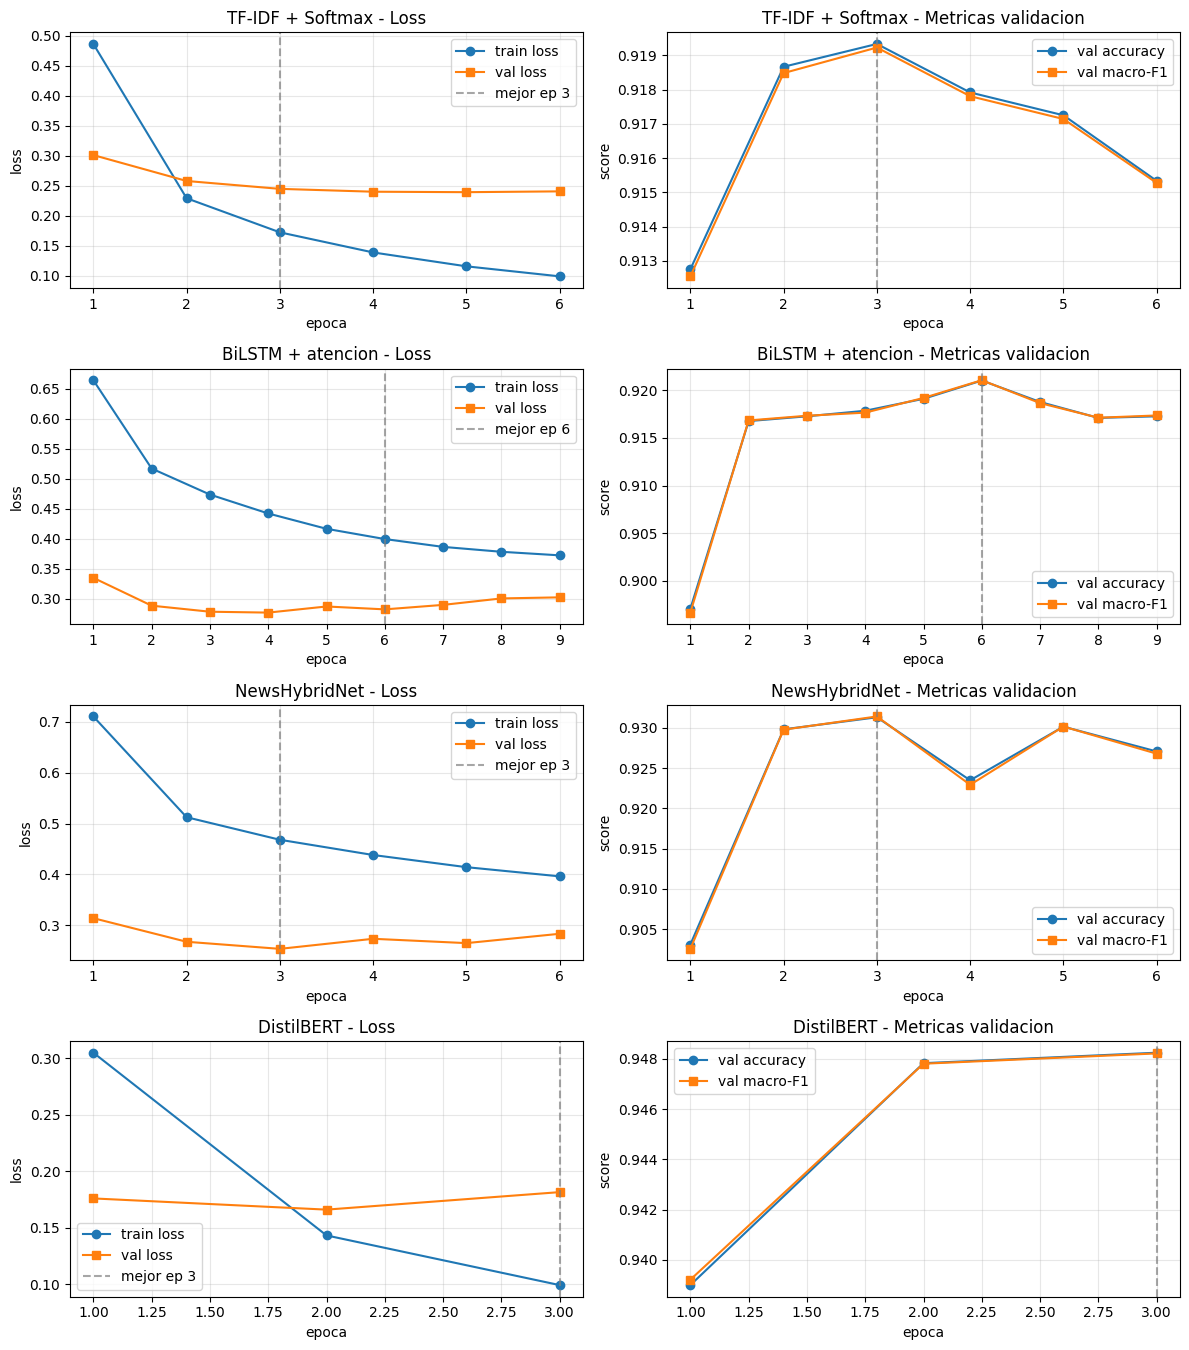

Figura guardada en /kaggle/working/curvas_aprendizaje.png


In [23]:
import matplotlib.pyplot as plt

def load_history(model_key):
    p = CKPT_ROOT / model_key / "history.json"
    if not p.exists():
        print(f"[SALTAR] no hay history.json para {model_key}")
        return None
    return json.load(open(p))

PLOT_MODELS = [
    ("tfidf_softmax", "TF-IDF + Softmax"),
    ("rnn_scratch",   "BiLSTM + atencion"),
    ("newshybridnet", "NewsHybridNet"),
    ("distilbert",    "DistilBERT"),
]

def plot_curves():
    present = [(k, n, load_history(k)) for k, n in PLOT_MODELS]
    present = [(k, n, h) for k, n, h in present if h]
    if not present:
        print("Sin history.json todavia; ejecuta el entrenamiento primero.")
        return
    rows = len(present)
    fig, axes = plt.subplots(rows, 2, figsize=(12, 3.4 * rows))
    if rows == 1:
        axes = axes.reshape(1, 2)
    for i, (k, name, h) in enumerate(present):
        ep = [r["epoch"] for r in h]
        tr = [r.get("train_loss") for r in h]
        vl = [r.get("loss") for r in h]
        f1 = [r.get("macro_f1") for r in h]
        ac = [r.get("accuracy") for r in h]
        best_ep = ep[int(np.argmax(f1))] if f1 else None
        ax = axes[i][0]
        ax.plot(ep, tr, marker="o", label="train loss")
        ax.plot(ep, vl, marker="s", label="val loss")
        if best_ep: ax.axvline(best_ep, ls="--", c="gray", alpha=0.7, label=f"mejor ep {best_ep}")
        ax.set_title(f"{name} - Loss"); ax.set_xlabel("epoca"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=0.3)
        ax = axes[i][1]
        ax.plot(ep, ac, marker="o", label="val accuracy")
        ax.plot(ep, f1, marker="s", label="val macro-F1")
        if best_ep: ax.axvline(best_ep, ls="--", c="gray", alpha=0.7)
        ax.set_title(f"{name} - Metricas validacion"); ax.set_xlabel("epoca"); ax.set_ylabel("score"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "curvas_aprendizaje.png", dpi=130, bbox_inches="tight")
    plt.show()
    print("Figura guardada en", OUTPUT_DIR / "curvas_aprendizaje.png")

plot_curves()


## 8.2 Recursos computacionales y tiempo de entrenamiento

Lineamiento del profesor: reportar **hardware (CPU, GPU, RAM)** y **tiempo de entrenamiento
aproximado**. El tiempo total por modelo se estima sumando el tiempo por epoca registrado en cada
`history.json` (campo `epoch_seconds` si existe; si no, se informa solo el entorno).

In [24]:
import platform

def hardware_report():
    info = {}
    info["os"] = platform.platform()
    info["python"] = platform.python_version()
    info["cpu"] = platform.processor() or "desconocido"
    try:
        info["cpu_cores"] = os.cpu_count()
    except Exception:
        pass
    if torch.cuda.is_available():
        info["gpu"] = torch.cuda.get_device_name(0)
        props = torch.cuda.get_device_properties(0)
        info["gpu_mem_GB"] = round(props.total_memory / 1e9, 2)
    else:
        info["gpu"] = "no disponible (CPU)"
    try:
        import psutil
        info["ram_GB"] = round(psutil.virtual_memory().total / 1e9, 2)
    except Exception:
        try:
            with open("/proc/meminfo") as f:
                kb = int(f.readline().split()[1])
            info["ram_GB"] = round(kb / 1e6, 2)
        except Exception:
            info["ram_GB"] = "desconocido (instala psutil)"
    return info

def training_time_report():
    rows = []
    for k, name in PLOT_MODELS:
        h = load_history(k)
        if not h:
            continue
        secs = [r.get("epoch_seconds") for r in h if r.get("epoch_seconds")]
        total = sum(secs) if secs else None
        rows.append({"modelo": name, "epocas": len(h),
                     "tiempo_total_min": round(total/60, 2) if total else "n/d",
                     "seg_por_epoca": round(total/len(secs), 1) if secs else "n/d"})
    return pd.DataFrame(rows)

hw = hardware_report()
print("== Recursos computacionales ==")
for k, v in hw.items():
    print(f"  {k:12s}: {v}")

tt = training_time_report()
print("\n== Tiempo de entrenamiento por modelo ==")
print(tt.to_string(index=False) if len(tt) else "  (sin history.json todavia)")

with open(OUTPUT_DIR / "recursos_computacionales.json", "w") as f:
    json.dump({"hardware": hw, "tiempos": tt.to_dict(orient="records") if len(tt) else []}, f, indent=2)
print("\nGuardado en", OUTPUT_DIR / "recursos_computacionales.json")


== Recursos computacionales ==
  os          : Linux-6.18.55+-x86_64-with-glibc2.39
  python      : 3.13.16
  cpu         : x86_64
  cpu_cores   : 4
  gpu         : Tesla T4
  gpu_mem_GB  : 15.64
  ram_GB      : 33.66

== Tiempo de entrenamiento por modelo ==
           modelo  epocas  tiempo_total_min  seg_por_epoca
 TF-IDF + Softmax       6              2.47           24.7
BiLSTM + atencion       9              5.99           39.9
    NewsHybridNet       6              4.01           40.1
       DistilBERT       3             20.47          409.4

Guardado en /kaggle/working/recursos_computacionales.json


## 10. Ablaciones de NewsHybridNet

Para aislar el aporte de cada componente (seccion 5.6 del Anteproyecto) se entrenan variantes de
NewsHybridNet cambiando una sola cosa a la vez:

1. **emb_random**: embeddings aleatorios **entrenables** (sin fastText) -> mide el aporte del
   preentrenamiento lexico.
2. **no_branch_b**: se anula la rama lexica de n-gramas -> mide el aporte de la rama B.
3. **full** (referencia): la configuracion propuesta ya entrenada en la seccion 7.

Cada variante guarda su propio checkpoint en `checkpoints/ablation_<nombre>/` y se reanuda igual que
los demas. La comparacion se evalua en el test de AG News (y, en el notebook de evaluacion, en BBC).

In [25]:
# Variante de NewsHybridNet parametrizable para las ablaciones.
class NewsHybridNetAblation(NewsHybridNet):
    def __init__(self, emb_matrix, freeze_emb=True, use_branch_b=True, **kw):
        super().__init__(emb_matrix, **kw)
        self.use_branch_b = use_branch_b
        if not freeze_emb:
            # Reemplaza la embedding congelada por una entrenable con misma forma.
            vocab_size, emb_dim = emb_matrix.shape
            self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=self.pad_idx)
    def forward(self, x, lengths, ngram_values, ngram_offsets, return_gate=False):
        mask = (x != self.pad_idx).long()
        emb = self.embedding(x)
        a = F.gelu(self.adapter_ln(self.adapter(emb))); a = self.spatial_drop(a)
        a_t = a.transpose(1, 2)
        c = torch.cat([self.conv2(a_t), self.conv3(a_t), self.conv5(a_t)], dim=1).transpose(1, 2)
        c = F.relu(self.cat_ln(c))
        packed = nn.utils.rnn.pack_padded_sequence(c, lengths.cpu(), batch_first=True, enforce_sorted=False)
        g_out, _ = self.bigru(packed)
        g_out, _ = nn.utils.rnn.pad_packed_sequence(g_out, batch_first=True, total_length=x.size(1))
        att, _ = self.attn(g_out, mask)
        masked = g_out.masked_fill((mask == 0).unsqueeze(-1), float('-inf'))
        maxp, _ = masked.max(dim=1); maxp = torch.nan_to_num(maxp, neginf=0.0)
        h_a = torch.cat([att, maxp], dim=1)
        ha_p = self.proj_a(h_a)
        if self.use_branch_b:
            h_b = self.embbag(ngram_values, ngram_offsets)
            hb_p = self.proj_b(h_b)
            g = torch.sigmoid(self.gate(torch.cat([ha_p, hb_p], dim=1)))
            fused = g * ha_p + (1 - g) * hb_p
        else:
            g = torch.ones_like(ha_p)
            fused = ha_p
        logits = self.head(fused)
        return (logits, g) if return_gate else logits

def train_hybrid_variant(model, ckpt_name, epochs=12, lr=1e-3, patience=3):
    """Como train_hybrid pero con carpeta de checkpoint propia (para ablaciones/semillas)."""
    ckpt_dir = CKPT_ROOT / ckpt_name
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    optimizer = torch.optim.AdamW(build_param_groups(model, 1e-2), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(hyb_train_loader), pct_start=0.1)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    start_epoch, best_f1, history = load_checkpoint(ckpt_dir, model, optimizer, scheduler)
    bad = 0
    for epoch in range(start_epoch + 1, epochs + 1):
        model.train(); t0 = time.time(); running = 0.0
        for ids, lengths, vals, offs, y in hyb_train_loader:
            ids, lengths = ids.to(DEVICE), lengths.to(DEVICE)
            vals, offs, y = vals.to(DEVICE), offs.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(ids, lengths, vals, offs), y)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); scheduler.step()
            running += loss.item() * y.size(0)
        train_loss = running / len(train_text)
        val_m, _, _ = evaluate_hybrid(model, hyb_val_loader)
        dt = time.time() - t0
        print(f"[{ckpt_name}] epoca {epoch:02d}/{epochs} | train_loss {train_loss:.4f} | "
              f"val_macroF1 {val_m['macro_f1']:.4f} | {dt:.1f}s")
        history.append({"epoch": epoch, "train_loss": train_loss, "epoch_seconds": dt, **val_m})
        is_best = val_m["macro_f1"] > best_f1
        if is_best: best_f1 = val_m["macro_f1"]; bad = 0
        else: bad += 1
        save_checkpoint(ckpt_dir, model, optimizer, scheduler, epoch, best_f1, history, is_best=is_best)
        if bad >= patience:
            print(f"[{ckpt_name}] early stopping en epoca {epoch}."); break
    return history

@torch.no_grad()
def test_variant(model, ckpt_name):
    best = torch.load(CKPT_ROOT / ckpt_name / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(best["model_state"])
    m, _, _ = evaluate_hybrid(model, hyb_test_loader)
    return m


In [26]:
# Entrena las dos ablaciones (la 'full' es la de la seccion 7). Ajusta EPOCHS_ABL si hay poco tiempo.
EPOCHS_ABL = 12
ablation_results = {}

set_seed()
abl_random = NewsHybridNetAblation(emb_tensor, freeze_emb=False, use_branch_b=True).to(DEVICE)
train_hybrid_variant(abl_random, "ablation_emb_random", epochs=EPOCHS_ABL)
ablation_results["emb_random (entrenable)"] = test_variant(abl_random, "ablation_emb_random")

set_seed()
abl_nob = NewsHybridNetAblation(emb_tensor, freeze_emb=True, use_branch_b=False).to(DEVICE)
train_hybrid_variant(abl_nob, "ablation_no_branch_b", epochs=EPOCHS_ABL)
ablation_results["sin rama B (solo semantica)"] = test_variant(abl_nob, "ablation_no_branch_b")

# 'full' = resultado ya calculado en la seccion 7
try:
    ablation_results["full (fastText congelado + rama B)"] = hybrid_test
except NameError:
    ablation_results["full (fastText congelado + rama B)"] = test_variant(
        NewsHybridNet(emb_tensor).to(DEVICE), "newshybridnet")

abl_df = pd.DataFrame([
    {"variante": k, "accuracy": v["accuracy"], "macro_f1": v["macro_f1"]}
    for k, v in ablation_results.items()
])
abl_df.to_csv(OUTPUT_DIR / "ablaciones_newshybridnet.csv", index=False)
print(abl_df.to_string(index=False))


  [reanudar] no hay checkpoint en /kaggle/working/checkpoints/ablation_emb_random; empezando desde cero.
[ablation_emb_random] epoca 01/12 | train_loss 0.8700 | val_macroF1 0.8938 | 43.6s
  [checkpoint] epoca 1 guardada en /kaggle/working/checkpoints/ablation_emb_random  (NUEVO MEJOR)
[ablation_emb_random] epoca 02/12 | train_loss 0.5254 | val_macroF1 0.9145 | 43.7s
  [checkpoint] epoca 2 guardada en /kaggle/working/checkpoints/ablation_emb_random  (NUEVO MEJOR)
[ablation_emb_random] epoca 03/12 | train_loss 0.4660 | val_macroF1 0.9241 | 43.7s
  [checkpoint] epoca 3 guardada en /kaggle/working/checkpoints/ablation_emb_random  (NUEVO MEJOR)
[ablation_emb_random] epoca 04/12 | train_loss 0.4337 | val_macroF1 0.9224 | 43.5s
  [checkpoint] epoca 4 guardada en /kaggle/working/checkpoints/ablation_emb_random
[ablation_emb_random] epoca 05/12 | train_loss 0.4105 | val_macroF1 0.9229 | 43.5s
  [checkpoint] epoca 5 guardada en /kaggle/working/checkpoints/ablation_emb_random
[ablation_emb_random

## 11. Entrenamiento multi-semilla (media +/- desviacion)

El Anteproyecto pide reportar media y desviacion estandar sobre **varias semillas** para la
configuracion principal. Aqui se entrena NewsHybridNet con 3 semillas y se resume el test de AG News.
Es costoso: ajusta `SEEDS` y `EPOCHS_SEED` segun el tiempo disponible. Cada semilla tiene su propio
checkpoint, asi que se reanuda si la sesion se corta.

In [27]:
SEEDS = [30, 42, 123]
EPOCHS_SEED = 12
seed_metrics = []

for s in SEEDS:
    set_seed(s)
    name = f"seed_{s}_newshybridnet"
    model_s = NewsHybridNet(emb_tensor).to(DEVICE)
    train_hybrid_variant(model_s, name, epochs=EPOCHS_SEED)
    m = test_variant(model_s, name)
    seed_metrics.append({"seed": s, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
    print(f"seed {s}: acc={m['accuracy']:.4f} macroF1={m['macro_f1']:.4f}")

seed_df = pd.DataFrame(seed_metrics)
resumen = {
    "accuracy_media": seed_df['accuracy'].mean(), "accuracy_std": seed_df['accuracy'].std(ddof=0),
    "macro_f1_media": seed_df['macro_f1'].mean(), "macro_f1_std": seed_df['macro_f1'].std(ddof=0),
}
seed_df.to_csv(OUTPUT_DIR / "multisemilla_newshybridnet.csv", index=False)
print(seed_df.to_string(index=False))
print(f"\nNewsHybridNet sobre {len(SEEDS)} semillas:")
print(f"  accuracy = {resumen['accuracy_media']:.4f} +/- {resumen['accuracy_std']:.4f}")
print(f"  macro-F1 = {resumen['macro_f1_media']:.4f} +/- {resumen['macro_f1_std']:.4f}")


  [reanudar] no hay checkpoint en /kaggle/working/checkpoints/seed_30_newshybridnet; empezando desde cero.
[seed_30_newshybridnet] epoca 01/12 | train_loss 0.7101 | val_macroF1 0.9045 | 39.7s
  [checkpoint] epoca 1 guardada en /kaggle/working/checkpoints/seed_30_newshybridnet  (NUEVO MEJOR)
[seed_30_newshybridnet] epoca 02/12 | train_loss 0.5129 | val_macroF1 0.9281 | 39.8s
  [checkpoint] epoca 2 guardada en /kaggle/working/checkpoints/seed_30_newshybridnet  (NUEVO MEJOR)
[seed_30_newshybridnet] epoca 03/12 | train_loss 0.4686 | val_macroF1 0.9317 | 40.4s
  [checkpoint] epoca 3 guardada en /kaggle/working/checkpoints/seed_30_newshybridnet  (NUEVO MEJOR)
[seed_30_newshybridnet] epoca 04/12 | train_loss 0.4383 | val_macroF1 0.9297 | 39.7s
  [checkpoint] epoca 4 guardada en /kaggle/working/checkpoints/seed_30_newshybridnet
[seed_30_newshybridnet] epoca 05/12 | train_loss 0.4138 | val_macroF1 0.9287 | 39.7s
  [checkpoint] epoca 5 guardada en /kaggle/working/checkpoints/seed_30_newshybridne

## 9. Notas sobre los checkpoints y la reanudación

- Cada `train_*` llama a `load_checkpoint` al inicio. Si Kaggle corta la sesión a mitad del entrenamiento,
  basta con **volver a ejecutar la celda** (o el notebook completo): continuará desde la última época guardada.
- `last.pt` se escribe de forma **atómica** tras cada época, así que un corte durante el guardado no corrompe el archivo.
- `best.pt` guarda el mejor modelo por macro-F1 de validación; es el que se usa para evaluar en test y el que debe cargar la API.
- Para DistilBERT se guarda además `hf_best/` en formato Hugging Face (`from_pretrained`) para servir la API sin reconstruir la arquitectura a mano.
- Para **NewsHybridNet** se guardan `vocab.json`, `embeddings.npy` y `ngram_config.json` junto al checkpoint, de modo que la API pueda reconstruir el modelo y reproducir exactamente el preprocesamiento de ambas ramas.
- Todo vive bajo `/kaggle/working/checkpoints`, que Kaggle conserva como *output* del notebook y puedes descargar o versionar como *dataset*.
